# Homework Problem Set 3

**Due Wednesday of Week 9**

#### &#x2705; Write your name here

<!-- info warning success danger -->
<div class="alert alert-block alert-info">
    <b>READ THIS: Instructions for doing this homework</b>
    <br><br>
    You are responsible for tracking how you worked on each problem set, and grading your work accordingly.
    <br><br> 
    To earn full credit on your problem set, follow these instructions:
    <ol>
        <li><b>For each problem</b>, start working on it by yourself. During this time, it's okay to use
these resources:
            <ul>
                <li>Your classwork</li>
                <li>The class wiki</li>
                <li>Some online resources like code documentation, stack overflow, and Python tutorials, but don't use anything AI-generated! (yet)</li>
            </ul>
        </li>
        <li>If you get stuck, give at least 20 minutes of focused effort before consulting other resources.</li>
        <li>After 20 minutes of trying without making progress on your own, you can seek help.
            <ul>
                <li>Use these resources, and still earn full credit:
                    <ul>
                        <li>Use the course help hours.</li>
                        <li>Work together with a peer.</li>
                    </ul>
                </li>
                <li>Use these resources, and earn partial credit:
                    <ul>
                        <li>Review the provided example solution for your problem.</li>
                        <li>Review a peer's completed solution.</li>
                        <li>Use a generative AI resource (any bot that automatically generates code and/or explanations for you).</li>
                    </ul>
                </li>
                <li>Avoid doing this if at all possible:
                    <ul>
                        <li>Copy and use code directly from a resource that you couldn't write yourself (be honest with yourself).</li>
                    </ul>
                </li>
            </ul>
        </li>
        <li>Reset your resources and your 20 minutes <b>for each and every problem</b> in the problem set.</li>
        <li>After you are done, re-read each problem carefully. Double-check, does your work solve the problem that was posed? It's up to you to ensure it does. If you think you have a working solution, but you're not certain, design some tests! If you want to triple-check at this point, you can compare your work with the example solutions without any penalty.</li>
        <li>At the bottom of your problem set, fill out the self-grading rubric. For each problem, indicate:
            <ul>
                <li>Whether you were stuck for 20 minutes of focused effort before seeking help.</li>
                <li>The help resources that you used.</li>
                <li>How you verified that your solution was correct.</li>
            </ul>
        </li>
        <li>From these answers, compute your grade and self-report it at the bottom of your problem set.</li>
    </ol>
</div>

The models of string vibration and musical instruments you worked on over Weeks 4-6 were based on finite-difference methods and Fourier transforms.

In this homework, you will build on the code you and your group wrote during class to solve some additional problems related to these methods.

You can have some free starter code related to finite-difference methods, since we didn't get a chance to code that method much during class.

In [1]:
from matplotlib.animation import FuncAnimation
from IPython.display import Audio, Markdown
import matplotlib.pyplot as plt
from scipy.io import wavfile
from pathlib import Path
import numpy as np
import scipy

plt.close('all')

In [2]:
def string_create(leng, pluckp, dis):
    N = (leng*5)+1
    x = np.linspace(0,leng,N)

    condlist = [x <= pluckp, x > pluckp]
    funclist = [
        lambda x: (dis/pluckp)*x,
        lambda x: (dis)/(leng-pluckp)*(leng-x)
    ]
    
    y = np.piecewise(x,condlist,funclist)
    v = np.zeros(N)
    
    return x, y, v, N

def string_timestep(x,y,v,c,dt,N):
    accel = np.zeros(N)
    for i in range(1,N-1):
        accel[i] = (c**2)*((y[i+1]-2*y[i]+y[i-1])/((x[i]-x[i-1])**2))
    v += accel*dt
    y += v*dt
    
def animate(frame):
    plt.cla()
    string_timestep(x,y,v,wave_speed,dt,N)
    ax_anim.plot(x,y)
    ax_anim.set_ylim(ymin=-4,ymax=4)
    ax_anim.grid()
    
def string_height(height,x,y,v,c,dt,N):
    accel = np.zeros(N)
    for i in range(1,N-1):
        accel[i] = (c**2)*((y[i+1]-2*y[i]+y[i-1])/((x[i]-x[i-1])**2))
        
    v += accel*dt
    y += v*dt
    
    height = np.mean(y)
    
    return height

def damped_string(d,x,y,v,c,dt,N):
    accel = np.zeros(N)
    for i in range(1,N-1):
        accel[i] = (c**2)*((y[i+1]-2*y[i]+y[i-1])/((x[i]-x[i-1])**2)) - d*v[i]
    v += accel*dt
    y += v*dt

    #((y[i-1]-y[i])/(x[i]-x[i-1]))
    
def animate_decay(frame):
    plt.cla()
    damped_string(drag,x,y,v,wave_speed,dt,N)
    ax_anim.plot(x,y)
    ax_anim.set_ylim(ymin=-4,ymax=4)
    ax_anim.grid()
    
def damped_height(height,d,x,y,v,c,dt,N):
    y[0] = 0 ; y[-1] = 0 ; v[0] = 0 ; v[-1] = 0
    accel = np.zeros(N)
    for i in range(1,N-1):
        accel[i] = (c**2)*((y[i+1]-2*y[i]+y[i-1])/((x[i]-x[i-1])**2)) - d*v[i]
        
    v += accel*dt
    y += v*dt

    height = np.mean(y)

    return height

def load_audio():
    #The following code finds the .wav files in any personal Jupyter Notebook
    HW_dir = Path.cwd()

    banjo_file = HW_dir / 'data' / 'banjo-mono.wav'
    guitar_file = HW_dir / 'data' / 'guitar-mono.wav'

    #Defining all variables
    banjo_samplerate, banjo_data = wavfile.read(banjo_file)
    banjo_period = banjo_data.size/banjo_samplerate
    banjo_time = np.arange(0,banjo_data.size,1)/banjo_samplerate
    banjo = Audio(banjo_data,rate = banjo_samplerate)

    guitar_samplerate, guitar_data = wavfile.read(guitar_file)
    guitar_period = guitar_data.size/guitar_samplerate
    guitar_time = np.arange(0,guitar_data.size,1)/guitar_samplerate
    guitar = Audio(guitar_data,rate = guitar_samplerate)
    
    return banjo, banjo_data, banjo_period, banjo_samplerate, guitar, guitar_data, guitar_period, guitar_samplerate

#### &#x2705; Problem 1

Create an animation of the motion of a plucked string, with the string plucked at L/10 instead the middle of the string (L/2). 

In [4]:
length = 10
pluckpoint = 1
displacement = 2
wave_speed = 1
dt = 0.05

x, y, v, N = string_create(length, pluckpoint, displacement)

plt.rcParams["animation.html"] = "jshtml" 
plt.rcParams['figure.dpi'] = 100
plt.ioff()
fig_anim, ax_anim = plt.subplots()
    
FuncAnimation(fig_anim, animate, frames=int(length/dt))

#### &#x2705; Problem 2

Approximate the amplitude of the string as the mean y-value (`np.mean(y)`). Create a plot comparing the amplitude of the plucked strings over time (plucked at L/2 compared to plucked at L/10).

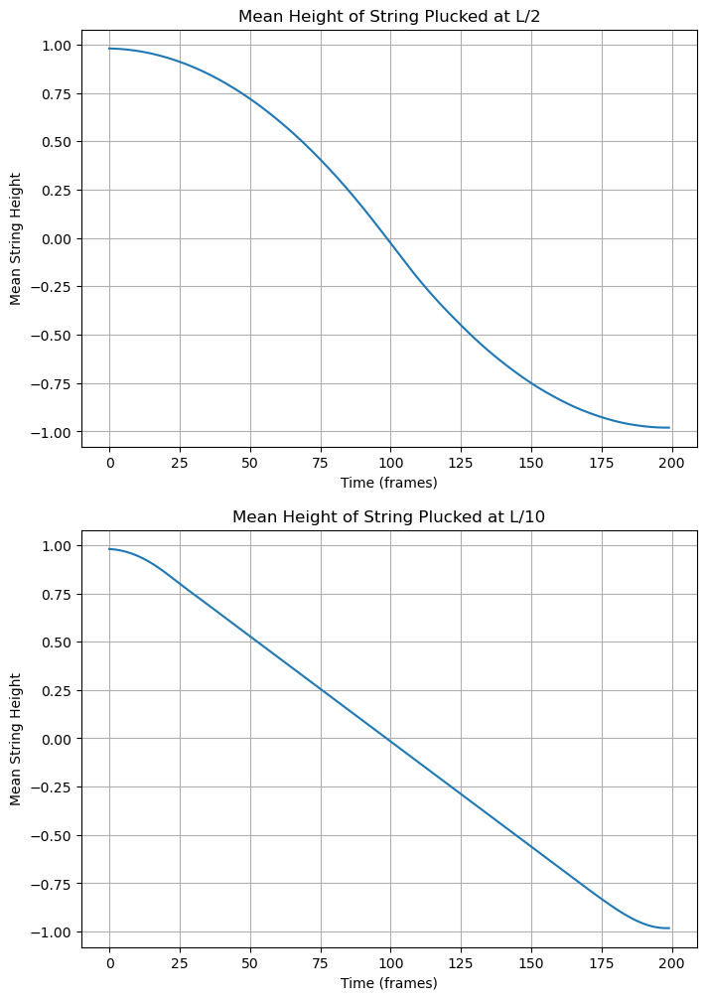

In [6]:
plt.close('all')
length = 10
pluckpoint2 = 5
pluckpoint10 = 1
displacement = 2
wave_speed = 1
dt = 0.05
time = np.arange(0,int(length/dt),1)

x2, y2, v2, N2 = string_create(length, pluckpoint2, displacement)
L2height = np.zeros(int(length/dt))

x10, y10, v10, N10 = string_create(length, pluckpoint10, displacement)
L10height = np.zeros(int(length/dt))

for i in range(0,int(length/dt)):
    L2height[i] = string_height(L2height,x2,y2,v2,wave_speed,dt,N2)

    L10height[i] = string_height(L10height,x10,y10,v10,wave_speed,dt,N10)
    
fig, ax = plt.subplots(2, 1, figsize=(8,12))

ax[0].plot(time,L2height)
ax[0].set( 
    xlabel='Time (frames)',
    ylabel='Mean String Height',
    title='Mean Height of String Plucked at L/2'
)
ax[0].grid()
        
ax[1].plot(time,L10height)
ax[1].set( 
    xlabel='Time (frames)',
    ylabel='Mean String Height',
    title='Mean Height of String Plucked at L/10'
)
ax[1].grid()

plt.show()
plt.close(fig);

#### &#x2705; Problem 3

Consider the updated wave equation below, which adds a *damping* term to the vibrations of the string. Incorporate this into your model, and create an amplitude plot to visualize the damped vibrations.

- Include at least 5 oscillations in your plot. 
- You can choose the location of the initial pluck.
- Choose a value for $\gamma$ that make the damping effect obvious in your plot.

$$\frac{\partial^2 y_i}{\partial t^2} = c^2 \frac{\partial^2 y_i}{\partial x^2} - \gamma \frac{\partial y_i}{\partial x}$$

In [9]:
drag = 0.2
length = 12
pluckpoint = 4
displacement = 2
wave_speed = 3
dt = 0.05

x, y, v, N = string_create(length, pluckpoint, displacement)

plt.close('all')
plt.rcParams["animation.html"] = "jshtml" 
plt.rcParams['figure.dpi'] = 100
plt.ioff()
fig_anim, ax_anim = plt.subplots()

FuncAnimation(fig_anim, animate_decay, frames=int(2*length/dt))

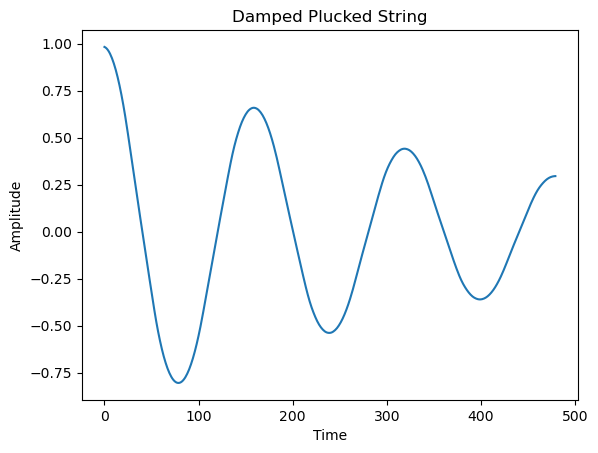

In [10]:
drag = 0.1
length = 12
pluckpoint = 4
displacement = 2
wave_speed = 3
dt = 0.05

x, y, v, N = string_create(length, pluckpoint, displacement)

time = np.arange(0,int(2*length/dt),1)
height = np.zeros(int(2*length/dt))

for i in range(0,int(2*length/dt)):
    height[i] = damped_height(height,drag,x,y,v,wave_speed,dt,N)

plt.close('all')
plt.plot(time,height)
plt.title('Damped Plucked String')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()

#### &#x2705; Problem 4

Extend the overall time span of the previous problem out to 1 second. Instead of plotting the amplitudes, play them out loud using `Ipython.display.Audio`.

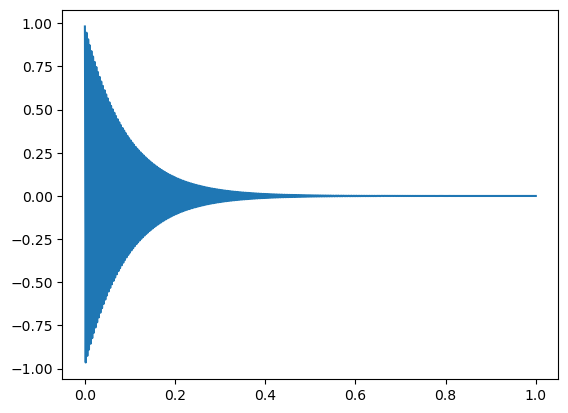

0.05


In [11]:
drag = 0.01
length = 12
pluckpoint = 2
displacement = 2
wave_speed = 3

samplerate = 44100
duration = 1
dt = 0.05

Nt = duration*samplerate
time = np.arange(0,Nt,1)/Nt

x, y, v, N = string_create(length, pluckpoint, displacement)
height = np.zeros(Nt)

for i in range(0,Nt):
    height[i] = damped_height(height,drag,x,y,v,wave_speed,dt,N)

plt.close('all')
plt.plot(time,height)
audio = height/np.max(np.abs(height))
string_audio = Audio(audio, rate=samplerate)
display(string_audio)
plt.show()

print(samplerate/(height.size/dt))

#### &#x2705; Problem 5

For this problem, use the frequency distributions from the guitar and banjo recordings. If needed, you can consult the code provided from ICA 6.2.

For this problem, discard the first frequency peak centered around 260 Hz from both instruments, and then play the audio out loud in the Jupyter notebook to hear the comparison.

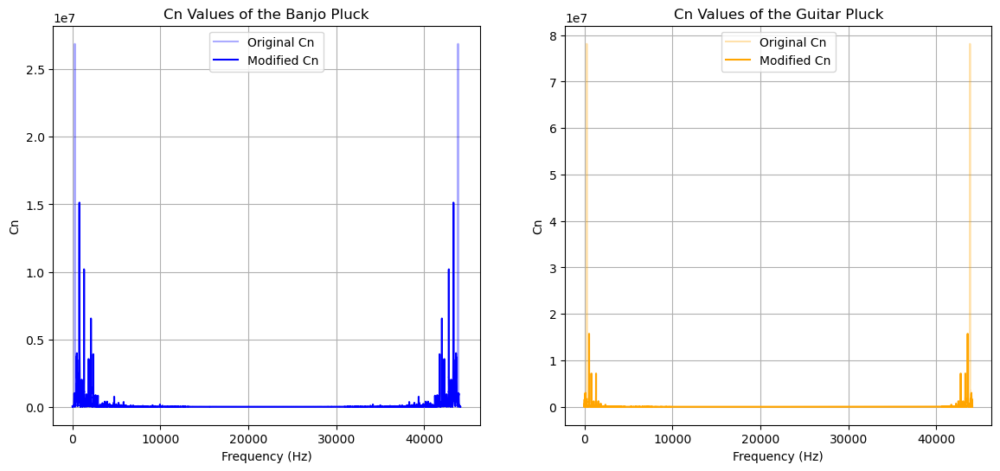

Original Banjo Audio

Modified Banjo Audio

Original Guitar Audio

Modified Guitar Audio

In [13]:
banjo_cutoffmin = 230
banjo_cutoffmax = 280
guitar_cutoffmin = 240
guitar_cutoffmax = 305

banjo, banjo_data, banjo_period, banjo_samplerate, guitar, guitar_data, guitar_period, guitar_samplerate = load_audio()

#Performs the fast fourier transform to calculate the Cn values of the audio file
cn_banjo = scipy.fft.fft(banjo_data)
Nb = np.arange(0,banjo_data.size)

cn_guitar = scipy.fft.fft(guitar_data)
Ng = np.arange(0,guitar_data.size)

#Removes specified frequencies
mod_cn_banjo = cn_banjo.copy()
mod_cn_guitar = cn_guitar.copy()

mod_cn_banjo[int(banjo_cutoffmin*banjo_period) : int(banjo_cutoffmax*banjo_period)] = 0
mod_cn_banjo[banjo_data.size-int(banjo_cutoffmax*banjo_period) : banjo_data.size-int(banjo_cutoffmin*banjo_period)] = 0

mod_cn_guitar[int(guitar_cutoffmin*guitar_period) : int(guitar_cutoffmax*guitar_period)] = 0
mod_cn_guitar[guitar_data.size-int(guitar_cutoffmax*guitar_period) : guitar_data.size-int(guitar_cutoffmin*guitar_period)] = 0
    
#Plots the Cn values along frequency
fig, ax = plt.subplots(1, 2, figsize=(14,6))

ax[0].plot(Nb/banjo_period, np.real(abs(cn_banjo)),color='blue',alpha=0.33,label='Original Cn')
ax[0].plot(Nb/banjo_period, np.real(abs(mod_cn_banjo)),color='blue',label='Modified Cn')
ax[0].set(
    xlabel='Frequency (Hz)',
    ylabel='Cn',
    title='Cn Values of the Banjo Pluck'
    
)
ax[0].legend()
ax[0].grid()
        
ax[1].plot(Ng/guitar_period, np.real(abs(cn_guitar)),color='orange',alpha=0.33,label='Original Cn')
ax[1].plot(Ng/guitar_period, np.real(abs(mod_cn_guitar)),color='orange',label='Modified Cn')
ax[1].set(
    xlabel='Frequency (Hz)',
    ylabel='Cn',
    title='Cn Values of the Guitar Pluck'
    
)
ax[1].legend()
ax[1].grid()

plt.show()
plt.close(fig);

#Reverses fft and displays audio
mod_banjo_reconstruct = scipy.fft.ifft(mod_cn_banjo)
mod_banjo_wav = Audio(mod_banjo_reconstruct, rate = banjo_samplerate)
display(Markdown('Original Banjo Audio'))
display(banjo)
display(Markdown('Modified Banjo Audio'))
display(mod_banjo_wav)

mod_guitar_reconstruct = scipy.fft.ifft(mod_cn_guitar)
mod_guitar_wav = Audio(mod_guitar_reconstruct, rate = guitar_samplerate)
display(Markdown('Original Guitar Audio'))
display(guitar)
display(Markdown('Modified Guitar Audio'))
display(mod_guitar_wav)

#### &#x2705; Problem 6

Again, use the frequency distributions from the guitar and banjo recordings. If needed, you can consult the code provided from ICA 6.2.

For this problem, combine the two frequency distributions together without truncating either of the audio files. Create a plot to ensure the frequency peaks are aligning with one another, and then play the resulting combined audio out loud in the Jupyter notebook.

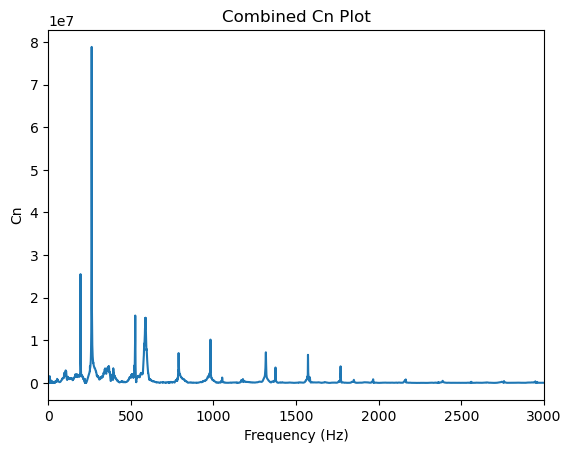

Combined Audio

In [14]:
cn_combined = np.zeros(guitar_data.size,dtype='complex')

wav_diff = guitar_data.size - banjo_data.size
banjo_size_correction = np.zeros(wav_diff)
cn_banjo_ext = np.append(cn_banjo,banjo_size_correction)
                         
cn_combined[:] = cn_guitar[:] + cn_banjo_ext[:]

plt.close('all')
plt.plot(Ng/guitar_period, np.real(abs(cn_combined)))
plt.title('Combined Cn Plot')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Cn')
plt.axis(xmin=0, xmax=3000)
plt.show()

combined_reconstruct = scipy.fft.ifft(cn_combined)
combined_wav = Audio(combined_reconstruct, rate = guitar_samplerate)
display(Markdown('Combined Audio'))
display(combined_wav)

## &#x2705; Self-grading

#### &#x2705; Self-grading Problem 1

For **Problem 1**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I didn't seek help from any outside sources.
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
It took be about 40 minutes to get the code to a place I liked. However, most of that time was converting my code to a function format.
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I only used my class notes.
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
No, I only copied my original code from notebooks and redid it to run in functions instead of as one long process.
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
Visually I can see that the code worked. I have also solved the fourier series of a triangle wave plucked at a point over time and acheived a similar result in the past.
```

#### &#x2705; Self-grading Problem 2

For **Problem 2**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I did not use any outside sources.
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
Yes, I spent around 25 minutes on this problem.
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I did not use any outside resources.
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
No, I did not copy any code.
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
I did sensemaking for the solution. When the string is plucked in the center, the tension is evenly distributed on both sides of the pluck point and crosses the x-axis uniformly. The pluck at the ends on the other hand has a higher tension on one side (facing the end point), so it is pulled below the x-axis sooner than the center pluck, creating a lower mean height faster than the center pluck. This is seen in the graphs where both plucks cause the same initial mean height, but the center pluck keeps the mean height larger for a longer period of time before both plucks cross the x-axis half way through the time.
```

#### &#x2705; Self-grading Problem 3

For **Problem 3**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I asked peers if they made the same change assumptions as I did. In the equation for the dampening, it uses the position derivative, however when trying this, the results were odd. On top of this, as far as I am aware, drag is always calculated with the time derivative. So, I just multiplied the drag coefficient by the current particles velocity to dampen the string instead of the position derivative equation. The result was much more in line with what I expected.
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I was stuck for around 30 minutes trying to figure out the position derivative problem, as I thought it might have been how I was approximating the finite difference of the first derivative. Eventually, as I said earlier, I chose to multiply it by the velocity.
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I talked with peers to see if they did the same thing.
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
I did not copy any code.
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
Visually, the string dampens over time in a way that maintains the plucks structure, so I think it is correct.
```

#### &#x2705; Self-grading Problem 4

For **Problem 4**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
Yes, I was struggling and looked up typical samplerates, audio levels, and timings online.
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I worked on this problem for about 2 hours. Something about the samplerate, and having to time my wave off of the samplerate really messed with me. Fo rthe longest time, I kept setting dt = 1/samplerate, which was causing the waves to only simulate for half a wavelength, but I didnt realize at the time, and thought that I was messing up the actual simulation equations, or that the rate with samplerate, duration, or Nt was messed up. But all I had to do was lower dt.
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I used google to look up typical samplerates and what types/format of data Ipython.display.Audio took as my audio player wouldnt let me click play in the beginning.
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
No, I did not.
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
I could hear the audio play, so I think I did it correctly. I also tested if the sound changed at different pluck positions, samplerates, drag coefficients, and they all did, so those expected properties worked as well.
```

#### &#x2705; Self-grading Problem 5

For **Problem 5**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
No did not
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I worked on the problem for about 45 minutes
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I didnt use any
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
No
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
By visually seeing that the largest spikes at the corresponding frequencies are missing
```

#### &#x2705; Self-grading Problem 6

For **Problem 6**, fill out your answers to these questions:

*Did you seek help from any people/resources? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I did not.
```

*Were stuck for 20 minutes of focused effort before seeking help? (Besides your class notes, the class wiki, and non-GenAI online resources.) **Yes, No, Other (explain).***

```
I worked on it for half an hour
```

*Which help resources did you use? Could be: course help hours, working together with a peer, the example solutions, a peer's completed solution, generative AI chatbot, other. **List resources, and explain if needed.***

```
I didnt use any
```

*Did you copy code directly without easily understanding it or modifying it, either from a solution, a peer's work, code found online, or an AI-generated resource? **Yes, No, Other (explain).***

```
No
```

*Did you verify that your solution was correct? If so how? Could be: Re-reading problem to verify desired outcome, making sense of the physics shown, carrying out tests of your code, consulting example solutions, other. **Yes (explain how), No (I trust my code without testing it out), Other (explain).***

```
I compared my solutions to a peer and we both had the same sound and cn graph.
```

#### That's all! You've reached the end of the homework.

Scroll through to make sure you didn't miss any tasks (marked with &#x2705;). Download your work as an HTML file, by selecting: `File` --> `Save and Export Notebook As...` --> `HTML` inside the JupyterHub interface (don't select your browser's File menu). 

Open your downloaded file to ensure the contents look okay, then submit it on Canvas.